### 1. Încărcarea bibliotecilor și identificarea fișierelor

Pentru început, am importat bibliotecile necesare pentru analiza datelor și am verificat ce fișiere sunt disponibile în datasetul Kaggle.

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/mkechinov/ecommerce-behavior-data-from-multi-category-store/2019-Nov.csv
/kaggle/input/datasets/mkechinov/ecommerce-behavior-data-from-multi-category-store/2019-Oct.csv


### 2. Citirea și explorarea inițială a datelor

Am încărcat primele 100.000 de înregistrări din fișierul pentru octombrie 2019, pentru a vedea cum sunt organizate datele. Am verificat numărul de exemple, numărul de caracteristici și primele rânduri din dataset.

In [2]:
import pandas as pd

fisier = "/kaggle/input/datasets/mkechinov/ecommerce-behavior-data-from-multi-category-store/2019-Oct.csv"

df = pd.read_csv(fisier, nrows=100000)

print("Număr de exemple:", len(df))
print("Număr de caracteristici:", len(df.columns))

df.head()

Număr de exemple: 100000
Număr de caracteristici: 9


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2019-10-01 00:00:00 UTC,view,44600062,2103807459595387724,NaN,shiseido,35.79,541312140,72d76fde-8bb3-4e00-8c23-a032dfed738c
1,2019-10-01 00:00:00 UTC,view,3900821,2053013552326770905,appliances.environment.water_heater,aqua,33.20,554748717,9333dfbd-b87a-4708-9857-6336556b0fcc
2,2019-10-01 00:00:01 UTC,view,17200506,2053013559792632471,furniture.living_room.sofa,NaN,543.10,519107250,566511c2-e2e3-422b-b695-cf8e6e792ca8
3,2019-10-01 00:00:01 UTC,view,1307067,2053013558920217191,computers.notebook,lenovo,251.74,550050854,7c90fc70-0e80-4590-96f3-13c02c18c713
4,2019-10-01 00:00:04 UTC,view,1004237,2053013555631882655,electronics.smartphone,apple,1081.98,535871217,c6bd7419-2748-4c56-95b4-8cec9ff8b80d


### 3. Verificarea structurii datelor și a valorilor lipsă

Am verificat tipurile de date ale celor 9 caracteristici și dacă există valori lipsă. Această analiză mă ajută să înțeleg mai bine datasetul și să identific eventualele probleme care trebuie rezolvate înainte de antrenarea modelelor de învățare automată.

In [3]:
print("Informații despre dataset:")
df.info()

print("\nValori lipsă pentru fiecare caracteristică:")
print(df.isnull().sum())

Informații despre dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   event_time     100000 non-null  object 
 1   event_type     100000 non-null  object 
 2   product_id     100000 non-null  int64  
 3   category_id    100000 non-null  int64  
 4   category_code  67413 non-null   object 
 5   brand          85607 non-null   object 
 6   price          100000 non-null  float64
 7   user_id        100000 non-null  int64  
 8   user_session   100000 non-null  object 
dtypes: float64(1), int64(3), object(5)
memory usage: 6.9+ MB

Valori lipsă pentru fiecare caracteristică:
event_time           0
event_type           0
product_id           0
category_id          0
category_code    32587
brand            14393
price                0
user_id              0
user_session         0
dtype: int64


### 4. Analiza tipurilor de evenimente

Am analizat câte evenimente de fiecare tip există în cele 100.000 de înregistrări din octombrie 2019. Am calculat atât numărul de evenimente, cât și procentul fiecăruia, pentru a observa cât de des utilizatorii vizualizează produse, le adaugă în coș sau le cumpără.

In [4]:
print("Distribuția tipurilor de evenimente:")
print(df["event_type"].value_counts())

print("\nProcente:")
print(df["event_type"].value_counts(normalize=True) * 100)

Distribuția tipurilor de evenimente:
event_type
view        97130
purchase     1655
cart         1215
Name: count, dtype: int64

Procente:
event_type
view        97.130
purchase     1.655
cart         1.215
Name: proportion, dtype: float64


### 5. Reprezentarea grafică a tipurilor de evenimente

Am realizat un grafic cu bare pentru a vizualiza distribuția tipurilor de evenimente din cele 100.000 de înregistrări analizate. Graficul mă ajută să observ mai ușor diferențele dintre numărul de vizualizări, adăugări în coș și achiziții.

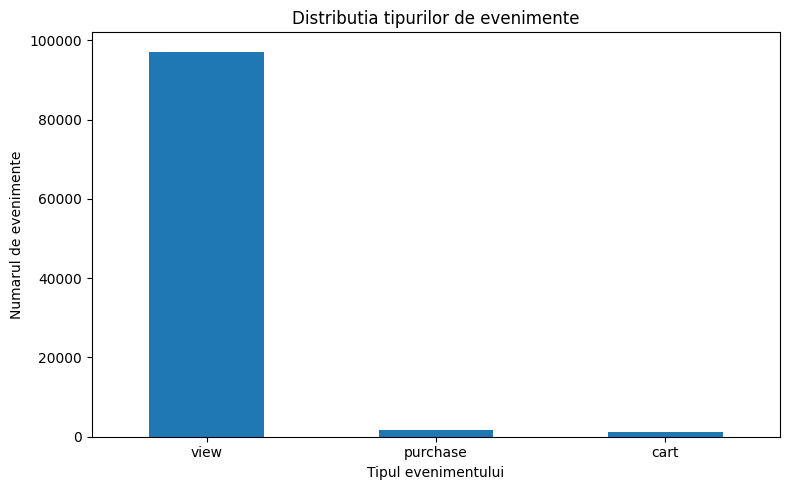

In [5]:
import matplotlib.pyplot as plt

df["event_type"].value_counts().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Distributia tipurilor de evenimente")
plt.xlabel("Tipul evenimentului")
plt.ylabel("Numarul de evenimente")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 6. Crearea unui eșantion din octombrie și noiembrie 2019

Deoarece datasetul original este foarte mare, am selectat câte 50.000 de înregistrări din fiecare lună, folosind citirea datelor pe bucăți. Am combinat apoi cele două eșantioane pentru a obține un set de 100.000 de exemple, pe care îl voi utiliza în continuarea analizei.

In [6]:

import pandas as pd
import numpy as np

baza = "/kaggle/input/datasets/mkechinov/ecommerce-behavior-data-from-multi-category-store/"

def esantion_luna(fisier, n=50000):
    bucati = []
    generator = np.random.default_rng(42)

    for chunk in pd.read_csv(baza + fisier, chunksize=500000):
        selectie = generator.random(len(chunk)) < 0.002
        bucati.append(chunk.loc[selectie])

    esantion = pd.concat(bucati, ignore_index=True)
    return esantion.sample(n=n, random_state=42)

octombrie = esantion_luna("2019-Oct.csv")
noiembrie = esantion_luna("2019-Nov.csv")

df = pd.concat([octombrie, noiembrie], ignore_index=True)

print("Număr total de exemple:", len(df))
print("Număr de caracteristici:", len(df.columns))
print(df["event_type"].value_counts())


Număr total de exemple: 100000
Număr de caracteristici: 9
event_type
view        95045
cart         3372
purchase     1583
Name: count, dtype: int64


### 7. Reprezentarea grafică a evenimentelor din cele două luni

Am realizat un grafic cu bare pentru a analiza distribuția evenimentelor din eșantionul combinat de 100.000 de înregistrări. Graficul arată diferențele dintre numărul de vizualizări, adăugări în coș și achiziții din datele selectate pentru octombrie și noiembrie 2019.

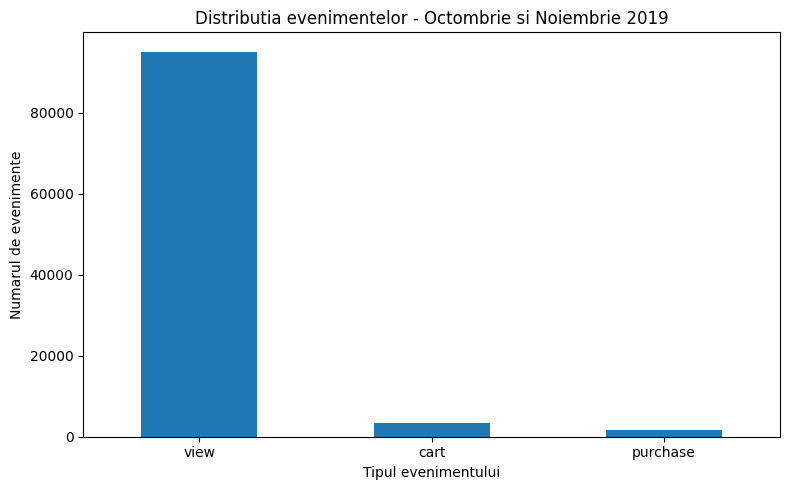

In [7]:
import matplotlib.pyplot as plt

df["event_type"].value_counts().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Distributia evenimentelor - Octombrie si Noiembrie 2019")
plt.xlabel("Tipul evenimentului")
plt.ylabel("Numarul de evenimente")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("/kaggle/working/distributia_evenimentelor.png", dpi=300, bbox_inches="tight")
plt.show()

### 8. Verificarea valorilor lipsă în eșantionul combinat

Am verificat valorile lipsă din eșantionul de 100.000 de înregistrări selectate din octombrie și noiembrie 2019. Această verificare mă ajută să identific caracteristicile care conțin date incomplete și care ar putea necesita prelucrare în etapele următoare ale proiectului.

In [8]:
print(df.isnull().sum())

event_time           0
event_type           0
product_id           0
category_id          0
category_code    31974
brand            14036
price                0
user_id              0
user_session         0
dtype: int64


### 9. Estimarea rezultatelor folosind un eșantion mai mic

În această etapă voi selecta aleatoriu 10.000 de înregistrări din eșantionul de 100.000. Voi calcula distribuția tipurilor de evenimente și voi folosi rezultatele pentru a estima distribuția în cele 100.000 de înregistrări.

Apoi voi compara estimările cu valorile reale și voi calcula erorile, pentru a observa cât de apropiate sunt rezultatele obținute din eșantionul mai mic.

In [9]:

# Selectăm aleatoriu 10.000 de exemple
df_mic = df.sample(n=10000, random_state=42)

# Numărăm evenimentele din eșantionul mic
numar_mic = df_mic["event_type"].value_counts()

# Estimăm numărul evenimentelor pentru 100.000 de exemple
estimare = numar_mic * 10

# Calculăm valorile reale
real = df["event_type"].value_counts()

# Comparăm rezultatele
comparatie = pd.DataFrame({
    "Estimare (din 10.000)": estimare,
    "Real (100.000)": real
}).fillna(0)

comparatie["Eroare absoluta"] = abs(
    comparatie["Estimare (din 10.000)"] -
    comparatie["Real (100.000)"]
)

comparatie["Eroare (%)"] = (
    comparatie["Eroare absoluta"] /
    comparatie["Real (100.000)"] * 100
).round(2)

print(comparatie)


            Estimare (din 10.000)  Real (100.000)  Eroare absoluta  Eroare (%)
event_type                                                                    
view                        95320           95045              275        0.29
cart                         3210            3372              162        4.80
purchase                     1470            1583              113        7.14


### Interpretarea rezultatelor

Am folosit un eșantion aleatoriu de 10.000 de înregistrări pentru a estima distribuția evenimentelor în setul de 100.000 de exemple.

Am comparat estimările cu valorile reale și am calculat erorile procentuale. Rezultatele arată că eroarea pentru vizualizări este de 0,29%, pentru adăugările în coș de 4,80%, iar pentru achiziții de 7,14%.

Observ că estimarea este foarte apropiată de valoarea reală în cazul vizualizărilor. Diferențele sunt mai mari pentru evenimentele mai puțin frecvente, precum adăugările în coș și achizițiile.

Această analiză arată că putem obține estimări utile dintr-un eșantion mai mic, dar precizia poate varia în funcție de frecvența evenimentelor.

# S6 – Verificarea 1: Primul model de Machine Learning

## 1. Obiectivul modelului

În această etapă voi construi prima versiune a unui model de Machine Learning pentru analiza comportamentului clienților dintr-un magazin online.

Scopul este să prezic dacă un utilizator va efectua o achiziție, folosind informații despre interacțiunile sale anterioare cu produsele.

Pentru început, voi pregăti datele, voi împărți exemplele în seturi de antrenare și testare, voi antrena un model de clasificare și voi evalua rezultatele.

Modelul inițial va reprezenta punctul de plecare pentru îmbunătățirile din etapa S9.

### 2. Verificarea datelor disponibile

Înainte să încep pregătirea modelului, voi verifica dacă datele folosite la analiza anterioară sunt încă disponibile în notebook.

Voi afișa coloanele setului de date și primele cinci înregistrări, pentru a vedea ce informații pot folosi în continuare.


In [10]:
# S6 - Verificarea 1
# Verificarea datelor disponibile pentru primul model
print("Variabila df exista:", "df" in globals())
print("Variabile DataFrame:", [n for n, v in globals().items() if isinstance(v, pd.DataFrame)])
print("Variabile disponibile:")
print(df.columns.tolist())

print("\nPrimele 5 inregistrari:")
display(df.head())

Variabila df exista: True
Variabile DataFrame: ['df', '_2', 'octombrie', 'noiembrie', 'df_mic', 'comparatie']
Variabile disponibile:
['event_time', 'event_type', 'product_id', 'category_id', 'category_code', 'brand', 'price', 'user_id', 'user_session']

Primele 5 inregistrari:


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2019-10-11 12:25:39 UTC,view,29100065,2053013565941482475,appliances.personal.massager,gezatone,203.35,554184344,eb561ad8-8ce8-4d98-89dd-c3238488bba4
1,2019-10-11 16:47:31 UTC,view,1004870,2053013555631882655,electronics.smartphone,samsung,285.44,536916271,55365847-52f8-4d4f-b6d1-866277418573
2,2019-10-19 16:35:05 UTC,view,24900170,2053013562183385881,NaN,eurolight,3.32,515271283,66cfe913-b4d6-4a65-8185-e28fee8555d3
3,2019-10-30 13:00:33 UTC,view,1002633,2053013555631882655,electronics.smartphone,apple,385.78,546718708,a5439e0f-5094-4741-8982-1273f644c1ca
4,2019-10-08 18:35:48 UTC,view,1005115,2053013555631882655,electronics.smartphone,apple,1015.46,558184751,05aed021-0319-49ef-b13c-31ac71a2cc65


### 3. Verificarea dimensiunii datelor și a tipurilor de evenimente

În continuare voi verifica numărul total de înregistrări și distribuția tipurilor de evenimente din setul de date.

Vreau să observ câte interacțiuni sunt de tip vizualizare, adăugare în coș și achiziție. Acest lucru mă va ajuta să înțeleg mai bine datele înainte de antrenarea modelului.

In [11]:
# S6 - Verificarea dimensiunii datelor si a claselor

print("Numar total de inregistrari:", len(df))

print("\nDistributia tipurilor de evenimente:")
print(df["event_type"].value_counts())

print("\nNumar de utilizatori unici:")
print(df["user_id"].nunique())

print("\nNumar de sesiuni unice:")
print(df["user_session"].nunique())

Numar total de inregistrari: 100000

Distributia tipurilor de evenimente:
event_type
view        95045
cart         3372
purchase     1583
Name: count, dtype: int64

Numar de utilizatori unici:
93989

Numar de sesiuni unice:
99315


### 4. Verificarea sesiunilor utilizatorilor

În această etapă voi analiza mai atent sesiunile utilizatorilor, folosind datele din luna octombrie 2019.

Voi verifica modul în care sunt grupate interacțiunile în cadrul sesiunilor, pentru a mă asigura că datele sunt pregătite corect pentru primul model de Machine Learning.

Această verificare este importantă deoarece vreau să prezic dacă într-o sesiune are loc cel puțin o achiziție.

In [12]:
# S6 - Verificarea sesiunilor consecutive

fisier_octombrie = (
    "/kaggle/input/datasets/mkechinov/"
    "ecommerce-behavior-data-from-multi-category-store/2019-Oct.csv"
)

coloane = [
    "event_time",
    "event_type",
    "product_id",
    "user_id",
    "user_session"
]

date_s6 = pd.read_csv(
    fisier_octombrie,
    usecols=coloane,
    nrows=200000
)

print("Numar de evenimente:", len(date_s6))

print("\nTipuri de evenimente:")
print(date_s6["event_type"].value_counts())

print("\nSesiuni cu cel putin 2 evenimente:")
numar_evenimente = date_s6.groupby("user_session").size()
print((numar_evenimente >= 2).sum())

print("\nSesiuni cu achizitii:")
print(
    date_s6.loc[
        date_s6["event_type"] == "purchase",
        "user_session"
    ].nunique()
)

Numar de evenimente: 200000

Tipuri de evenimente:
event_type
view        193377
purchase      3639
cart          2984
Name: count, dtype: int64

Sesiuni cu cel putin 2 evenimente:
30353

Sesiuni cu achizitii:
3127


### 5. Pregătirea sesiunilor pentru predicție

În această etapă voi verifica sesiunile utilizatorilor pentru a identifica datele care pot fi folosite la antrenarea modelului.

Mai întâi voi elimina înregistrările care nu au informațiile necesare despre sesiune sau momentul interacțiunii. Apoi voi transforma datele calendaristice într-un format potrivit pentru analiză.

Scopul este să pregătesc un set de date corect, pe baza căruia modelul să poată învăța să prezică dacă într-o sesiune va avea loc o achiziție.

In [13]:
# S6 - Verificarea sesiunilor care pot fi folosite pentru predictie

date_verificare = date_s6.dropna(
    subset=["user_session", "event_time"]
).copy()

date_verificare["event_time"] = pd.to_datetime(
    date_verificare["event_time"],
    utc=True
)

date_verificare = date_verificare.sort_values(
    "event_time",
    kind="stable"
)

# Verificam daca fiecare sesiune contine o achizitie
# si daca exista evenimente inainte de prima achizitie.

def verifica_sesiune(grup):
    achizitii = grup["event_type"].eq("purchase")

    if not achizitii.any():
        return pd.Series({
            "are_achizitie": False,
            "are_istoric_anterior": False
        })

    prima_achizitie = achizitii.to_numpy().argmax()

    return pd.Series({
        "are_achizitie": True,
        "are_istoric_anterior": prima_achizitie > 0
    })

rezultat_sesiuni = date_verificare.groupby(
    "user_session"
).apply(
    verifica_sesiune,
    include_groups=False
)

print("Sesiuni cu achizitie:",
      rezultat_sesiuni["are_achizitie"].sum())

print("Sesiuni cu achizitie si istoric anterior:",
      rezultat_sesiuni["are_istoric_anterior"].sum())

Sesiuni cu achizitie: 3127
Sesiuni cu achizitie si istoric anterior: 3086


### 6. Construirea setului de date pentru clasificare

În această etapă voi pregăti datele care vor fi folosite pentru antrenarea primului model de Machine Learning.

Voi grupa interacțiunile după sesiunea utilizatorului și voi păstra informații despre prima interacțiune din fiecare sesiune. De asemenea, voi verifica dacă în sesiunea respectivă a avut loc o achiziție.

Astfel, fiecare sesiune va reprezenta un exemplu pentru model, iar rezultatul pe care vreau să îl prezic va avea două valori: 1 dacă a existat o achiziție și 0 dacă nu a existat.

Acest set de date va fi folosit în continuare pentru antrenarea și testarea modelului de clasificare.

In [14]:
# S6 - Construirea primului set de date pentru clasificare

# Pastram sesiunile cu identificator valid
date_model = date_verificare.dropna(
    subset=["user_session"]
).copy()

# Prima interactiune din fiecare sesiune
primele_evenimente = (
    date_model.groupby("user_session", sort=False)
    .first()
    .reset_index()
)

# Eticheta: exista o achizitie ulterior in aceeasi sesiune?
sesiuni_cu_achizitie = set(
    date_model.loc[
        date_model["event_type"] == "purchase",
        "user_session"
    ]
)

primele_evenimente["purchase_later"] = (
    primele_evenimente["user_session"]
    .isin(sesiuni_cu_achizitie)
    & primele_evenimente["event_type"].ne("purchase")
).astype(int)

# Pentru acest prim experiment folosim sesiuni
# care incep cu o vizualizare de produs.
date_clasificare = primele_evenimente[
    primele_evenimente["event_type"] == "view"
].copy()

print("Numar exemple:", len(date_clasificare))

print("\nDistributia claselor:")
print(date_clasificare["purchase_later"].value_counts())

print("\nPrimele exemple:")
display(
    date_clasificare[
        ["event_time", "product_id", "purchase_later"]
    ].head()
)

Numar exemple: 47646

Distributia claselor:
purchase_later
0    44564
1     3082
Name: count, dtype: int64

Primele exemple:


,event_time,product_id,purchase_later
0,2019-10-01 00:00:00+00:00,44600062,0
1,2019-10-01 00:00:00+00:00,3900821,0
2,2019-10-01 00:00:01+00:00,17200506,0
3,2019-10-01 00:00:01+00:00,1307067,0
4,2019-10-01 00:00:04+00:00,1004237,0


### 7. Conectarea la Weights & Biases pentru monitorizarea experimentelor

În această etapă voi conecta notebook-ul Kaggle la platforma Weights & Biases (W&B), pe care o voi folosi pentru a salva și urmări rezultatele modelelor de Machine Learning.

Pentru conectare voi utiliza o cheie API stocată în Kaggle Secrets, astfel încât să nu fie necesar să introduc cheia direct în cod.

După autentificare, voi putea înregistra rezultatele primului model și le voi putea compara ulterior cu cele obținute în etapa S9.

In [15]:
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
api_key = user_secrets.get_secret("WANDB_API_KEY")

print("Cheia Weights & Biases a fost accesată cu succes!")

Cheia Weights & Biases a fost accesată cu succes!


In [16]:
%pip install -q wandb

import wandb

wandb.login(key=api_key)

print("Conectarea la Weights & Biases a reușit!")

Note: you may need to restart the kernel to use updated packages.


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: teodorapeanca (teodorapeanca-university-of-craiova) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Conectarea la Weights & Biases a reușit!


In [17]:
run = wandb.init(
    entity="teodorapeanca-university-of-craiova",
    project="ECommerce-Customer-Behavior-ML",
    name="S6-Primul-Model",
    job_type="training",
    config={
        "etapa": "S6",
        "obiectiv": "Predictia achizitiilor",
        "numar_exemple": len(date_clasificare)
    }
)

print("Experimentul S6 a fost initializat!")

wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261124_135637-6sgl6e0w
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run S6-Primul-Model
wandb: ⭐️ View project at https://wandb.ai/teodorapeanca-university-of-craiova/ECommerce-Customer-Behavior-ML
wandb: 🚀 View run at https://wandb.ai/teodorapeanca-university-of-craiova/ECommerce-Customer-Behavior-ML/runs/6sgl6e0w


Experimentul S6 a fost initializat!


### 8. Verificarea datelor înainte de antrenarea modelului

Înainte de antrenarea primului model, voi face câteva verificări suplimentare asupra setului de date pregătit.

Mai întâi voi transforma coloana cu data și ora evenimentelor într-un format potrivit pentru prelucrare și voi verifica perioada acoperită de înregistrări.

Apoi voi analiza distribuția celor două clase, pentru a vedea câte sesiuni au dus la o achiziție și câte nu.

Voi verifica și numărul de sesiuni, precum și ordinea cronologică a datelor, pentru a mă asigura că setul este pregătit pentru următoarele etape.

In [18]:
date_clasificare["event_time"] = pd.to_datetime(
    date_clasificare["event_time"], utc=True
)

print("Prima data:", date_clasificare["event_time"].min())
print("Ultima data:", date_clasificare["event_time"].max())
print("Numar exemple:", len(date_clasificare))

Prima data: 2019-10-01 00:00:00+00:00
Ultima data: 2019-10-01 06:06:57+00:00
Numar exemple: 47646


In [19]:
print("Coloanele disponibile:")
print(date_clasificare.columns.tolist())

print("\nDistribuția claselor:")
print(date_clasificare["purchase_later"].value_counts())

print("\nPrimele exemple:")
display(date_clasificare.head())

Coloanele disponibile:
['user_session', 'event_time', 'event_type', 'product_id', 'user_id', 'purchase_later']

Distribuția claselor:
purchase_later
0    44564
1     3082
Name: count, dtype: int64

Primele exemple:


,user_session,event_time,event_type,product_id,user_id,purchase_later
0,72d76fde-8bb3-4e00-8c23-a032dfed738c,2019-10-01 00:00:00+00:00,view,44600062,541312140,0
1,9333dfbd-b87a-4708-9857-6336556b0fcc,2019-10-01 00:00:00+00:00,view,3900821,554748717,0
2,566511c2-e2e3-422b-b695-cf8e6e792ca8,2019-10-01 00:00:01+00:00,view,17200506,519107250,0
3,7c90fc70-0e80-4590-96f3-13c02c18c713,2019-10-01 00:00:01+00:00,view,1307067,550050854,0
4,c6bd7419-2748-4c56-95b4-8cec9ff8b80d,2019-10-01 00:00:04+00:00,view,1004237,535871217,0


In [20]:
print("Datele sunt ordonate cronologic:",
      date_model["event_time"].is_monotonic_increasing)

print("Numar sesiuni:",
      date_model["user_session"].nunique())

print("Numar exemple clasificare:",
      len(date_clasificare))

Datele sunt ordonate cronologic: True
Numar sesiuni: 47697
Numar exemple clasificare: 47646


### 9. Pregătirea caracteristicilor pentru primul model

În această etapă voi selecta informațiile pe care modelul de Machine Learning le va folosi pentru a face predicții.

Pentru primul experiment voi utiliza două caracteristici: ora la care a început interacțiunea și ziua săptămânii în care aceasta a avut loc.

Aceste informații vor reprezenta datele de intrare ale modelului (X).

Separat, voi păstra variabila `purchase_later`, care indică dacă în sesiunea respectivă a avut loc ulterior o achiziție. Aceasta va reprezenta rezultatul pe care modelul trebuie să îl prezică (y).

La final voi verifica dimensiunile celor două seturi, pentru a mă asigura că datele sunt pregătite pentru antrenare.

In [21]:
# S6 - Pregatirea caracteristicilor pentru primul model

date_clasificare["ora"] = date_clasificare["event_time"].dt.hour
date_clasificare["zi_saptamana"] = date_clasificare["event_time"].dt.dayofweek

X = date_clasificare[["ora", "zi_saptamana"]].copy()
y = date_clasificare["purchase_later"].copy()

print("Dimensiunea caracteristicilor:", X.shape)
print("Dimensiunea etichetelor:", y.shape)

print("\nPrimele caracteristici:")
display(X.head())

Dimensiunea caracteristicilor: (47646, 2)
Dimensiunea etichetelor: (47646,)

Primele caracteristici:


,ora,zi_saptamana
0,0,1
1,0,1
2,0,1
3,0,1
4,0,1


### 10. Împărțirea datelor în seturi de antrenare și testare

În această etapă voi împărți datele în două seturi, pentru a putea antrena modelul și apoi verifica rezultatele obținute.

Voi folosi 80% dintre exemple pentru antrenare și 20% pentru testare. Astfel, modelul va învăța pe un set de date, iar evaluarea se va face pe exemple care nu au fost folosite la antrenare.

Voi utiliza parametrul `stratify=y` pentru a păstra aproximativ aceeași proporție a sesiunilor cu achiziții și fără achiziții în ambele seturi.

La final voi verifica numărul de exemple și procentul achizițiilor din fiecare set.

In [22]:
# S6 - Impartirea datelor in antrenare si testare

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Exemple pentru antrenare:", len(X_train))
print("Exemple pentru testare:", len(X_test))

print("\nProcent achizitii in antrenare:",
      round(y_train.mean() * 100, 2), "%")

print("Procent achizitii in testare:",
      round(y_test.mean() * 100, 2), "%")

Exemple pentru antrenare: 38116
Exemple pentru testare: 9530

Procent achizitii in antrenare: 6.47 %
Procent achizitii in testare: 6.46 %


### 11. Antrenarea primului model de Machine Learning

În această etapă voi antrena primul model de clasificare, folosind algoritmul Logistic Regression din biblioteca Scikit-learn.

Am ales acest algoritm deoarece este relativ simplu și potrivit pentru un prim experiment de clasificare binară, în care vreau să prezic dacă o sesiune se va încheia cu o achiziție.

Voi utiliza parametrul `class_weight="balanced"` deoarece numărul sesiunilor fără achiziții este mult mai mare decât cel al sesiunilor cu achiziții. Astfel, modelul va acorda o importanță mai mare clasei mai puțin reprezentate.

După antrenarea pe setul de antrenare, voi folosi modelul pentru a realiza predicții pe setul de testare.

Rezultatele obținute vor fi evaluate în etapa următoare, pentru a vedea cât de bine reușește modelul să identifice sesiunile care conțin achiziții.

In [23]:
# S6 - Antrenarea primului model de clasificare

from sklearn.linear_model import LogisticRegression

model_s6 = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

model_s6.fit(X_train, y_train)

y_pred = model_s6.predict(X_test)

print("Primul model ML a fost antrenat cu succes!")
print("Algoritm: Logistic Regression")
print("Exemple antrenare:", len(X_train))
print("Exemple testare:", len(X_test))
print("Predictii generate:", len(y_pred))

Primul model ML a fost antrenat cu succes!
Algoritm: Logistic Regression
Exemple antrenare: 38116
Exemple testare: 9530
Predictii generate: 9530


### 12. Evaluarea performanței primului model

După antrenarea modelului Logistic Regression, voi evalua rezultatele obținute pe setul de testare.

Pentru evaluare voi folosi patru indicatori:

- **Accuracy** – arată procentul total al predicțiilor corecte.
- **Precision** – arată câte dintre sesiunile prezise ca având achiziții au avut într-adevăr o achiziție.
- **Recall** – arată câte dintre sesiunile cu achiziții reale au fost identificate corect de model.
- **F1-score** – combină Precision și Recall într-un singur indicator.

Voi analiza și matricea de confuzie, pentru a observa câte predicții au fost corecte și câte au fost greșite.

Deoarece sesiunile cu achiziții sunt mai puțin frecvente, nu mă voi baza doar pe Accuracy, ci voi urmări în special Precision, Recall și F1-score.

Rezultatele acestui prim model vor reprezenta un punct de plecare pentru îmbunătățirile din etapa S9.

In [24]:
# S6 - Evaluarea primului model de Machine Learning

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("Rezultatele primului model ML:")
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))

print("\nMatricea de confuzie:")
print(confusion_matrix(y_test, y_pred))

print("\nRaport complet de clasificare:")
print(classification_report(y_test, y_pred, zero_division=0))

Rezultatele primului model ML:
Accuracy: 0.4041
Precision: 0.0681
Recall: 0.6477
F1-score: 0.1232

Matricea de confuzie:
[[3452 5462]
 [ 217  399]]

Raport complet de clasificare:
              precision    recall  f1-score   support

           0       0.94      0.39      0.55      8914
           1       0.07      0.65      0.12       616

    accuracy                           0.40      9530
   macro avg       0.50      0.52      0.34      9530
weighted avg       0.88      0.40      0.52      9530



### 13. Înregistrarea rezultatelor în Weights & Biases

După evaluarea modelului, voi înregistra rezultatele obținute în platforma Weights & Biases (Forge).

Voi salva valorile pentru Accuracy, Precision, Recall și F1-score, împreună cu numărul de exemple folosite pentru antrenare și testare.

Astfel, voi putea urmări performanța primului model și voi avea posibilitatea să compar rezultatele cu cele ale modelelor îmbunătățite în etapa S9.

In [25]:
# S6 - Inregistrarea rezultatelor in Weights & Biases

run.log({
    "accuracy": accuracy,
    "precision": precision,
    "recall": recall,
    "f1_score": f1,
    "train_samples": len(X_train),
    "test_samples": len(X_test)
})

print("Rezultatele modelului S6 au fost trimise in Forge!")

Rezultatele modelului S6 au fost trimise in Forge!


### 14. Finalizarea experimentului

La final voi închide experimentul S6 din Weights & Biases, după înregistrarea tuturor rezultatelor.

În acest fel, rezultatele primului model vor rămâne salvate și vor putea fi consultate ulterior.

Modelul Logistic Regression reprezintă prima versiune a sistemului de predicție. În etapa S9 voi încerca să îmbunătățesc performanța acestuia prin utilizarea unor caracteristici suplimentare și compararea mai multor algoritmi de clasificare.

In [26]:
# S6 - Finalizarea experimentului in Weights & Biases

run.finish()

print("Experimentul S6 a fost finalizat!")

wandb: updating run metadata
wandb: uploading wandb-metadata.json; uploading requirements.txt; uploading output.log; uploading wandb-summary.json; uploading config.yaml
wandb: 
wandb: Run history:
wandb:      accuracy ▁
wandb:      f1_score ▁
wandb:     precision ▁
wandb:        recall ▁
wandb:  test_samples ▁
wandb: train_samples ▁
wandb: 
wandb: Run summary:
wandb:      accuracy 0.40409
wandb:      f1_score 0.12321
wandb:     precision 0.06808
wandb:        recall 0.64773
wandb:  test_samples 9530
wandb: train_samples 38116
wandb: 
wandb: 🚀 View run S6-Primul-Model at: https://wandb.ai/teodorapeanca-university-of-craiova/ECommerce-Customer-Behavior-ML/runs/6sgl6e0w
wandb: ⭐️ View project at: https://wandb.ai/teodorapeanca-university-of-craiova/ECommerce-Customer-Behavior-ML
wandb: Synced 5 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20261124_135637-6sgl6e0w/logs


Experimentul S6 a fost finalizat!


# S9 – Verificarea 2: Îmbunătățirea modelului de Machine Learning

## 1. Obiectivul etapei S9

În această etapă voi încerca să îmbunătățesc performanța primului model de Machine Learning realizat în etapa S6.

Voi utiliza caracteristici suplimentare pentru a prezice dacă un utilizator va efectua o achiziție în cadrul unei sesiuni.

Voi testa mai mulți algoritmi de clasificare și diferite configurații ale hiperparametrilor, pentru a identifica modelul care oferă cele mai bune rezultate.

Rezultatele obținute vor fi înregistrate în Weights & Biases și comparate cu rezultatele modelului inițial din etapa S6.

## 2. Pregătirea datelor pentru modelul îmbunătățit

Pentru a putea compara rezultatele cu cele obținute în etapa S6, voi porni de la același set de date și voi păstra același obiectiv de clasificare.

În prima versiune a modelului am utilizat doar ora și ziua săptămânii. În această etapă voi analiza posibilitatea de a introduce caracteristici suplimentare, disponibile în momentul primei vizualizări a unui produs.

Voi avea grijă să nu folosesc informații despre evenimentele ulterioare pentru realizarea predicției.

In [27]:
# S9 - Verificarea datelor disponibile

print("Setul de date S6 este disponibil:",
      "date_clasificare" in globals())

if "date_clasificare" in globals():
    print("Numar de exemple:", len(date_clasificare))

    print("\nCaracteristici disponibile:")
    print(date_clasificare.columns.tolist())

    print("\nDistributia claselor:")
    print(date_clasificare["purchase_later"].value_counts())

    print("\nPrimele 5 exemple:")
    display(date_clasificare.head())

Setul de date S6 este disponibil: True
Numar de exemple: 47646

Caracteristici disponibile:
['user_session', 'event_time', 'event_type', 'product_id', 'user_id', 'purchase_later', 'ora', 'zi_saptamana']

Distributia claselor:
purchase_later
0    44564
1     3082
Name: count, dtype: int64

Primele 5 exemple:


,user_session,event_time,event_type,product_id,user_id,purchase_later,ora,zi_saptamana
0,72d76fde-8bb3-4e00-8c23-a032dfed738c,2019-10-01 00:00:00+00:00,view,44600062,541312140,0,0,1
1,9333dfbd-b87a-4708-9857-6336556b0fcc,2019-10-01 00:00:00+00:00,view,3900821,554748717,0,0,1
2,566511c2-e2e3-422b-b695-cf8e6e792ca8,2019-10-01 00:00:01+00:00,view,17200506,519107250,0,0,1
3,7c90fc70-0e80-4590-96f3-13c02c18c713,2019-10-01 00:00:01+00:00,view,1307067,550050854,0,0,1
4,c6bd7419-2748-4c56-95b4-8cec9ff8b80d,2019-10-01 00:00:04+00:00,view,1004237,535871217,0,0,1


In [28]:
# S9 - Identificarea caracteristicilor suplimentare

print("Caracteristici disponibile in dataset:")
print(df.columns.tolist())

print("\nPrimele 5 exemple:")
display(df.head())

Caracteristici disponibile in dataset:
['event_time', 'event_type', 'product_id', 'category_id', 'category_code', 'brand', 'price', 'user_id', 'user_session']

Primele 5 exemple:


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2019-10-11 12:25:39 UTC,view,29100065,2053013565941482475,appliances.personal.massager,gezatone,203.35,554184344,eb561ad8-8ce8-4d98-89dd-c3238488bba4
1,2019-10-11 16:47:31 UTC,view,1004870,2053013555631882655,electronics.smartphone,samsung,285.44,536916271,55365847-52f8-4d4f-b6d1-866277418573
2,2019-10-19 16:35:05 UTC,view,24900170,2053013562183385881,NaN,eurolight,3.32,515271283,66cfe913-b4d6-4a65-8185-e28fee8555d3
3,2019-10-30 13:00:33 UTC,view,1002633,2053013555631882655,electronics.smartphone,apple,385.78,546718708,a5439e0f-5094-4741-8982-1273f644c1ca
4,2019-10-08 18:35:48 UTC,view,1005115,2053013555631882655,electronics.smartphone,apple,1015.46,558184751,05aed021-0319-49ef-b13c-31ac71a2cc65


In [29]:
# S9 - Incarcarea datelor cu caracteristici suplimentare

coloane_s9 = [
    "event_time",
    "event_type",
    "product_id",
    "user_id",
    "user_session",
    "price",
    "category_code",
    "brand"
]

date_s9 = pd.read_csv(
    fisier_octombrie,
    usecols=coloane_s9,
    nrows=200000
)

print("Numar de evenimente:", len(date_s9))
print("Numar de caracteristici:", len(date_s9.columns))

display(date_s9.head())

Numar de evenimente: 200000
Numar de caracteristici: 8


,event_time,event_type,product_id,category_code,brand,price,user_id,user_session
0,2019-10-01 00:00:00 UTC,view,44600062,NaN,shiseido,35.79,541312140,72d76fde-8bb3-4e00-8c23-a032dfed738c
1,2019-10-01 00:00:00 UTC,view,3900821,appliances.environment.water_heater,aqua,33.20,554748717,9333dfbd-b87a-4708-9857-6336556b0fcc
2,2019-10-01 00:00:01 UTC,view,17200506,furniture.living_room.sofa,NaN,543.10,519107250,566511c2-e2e3-422b-b695-cf8e6e792ca8
3,2019-10-01 00:00:01 UTC,view,1307067,computers.notebook,lenovo,251.74,550050854,7c90fc70-0e80-4590-96f3-13c02c18c713
4,2019-10-01 00:00:04 UTC,view,1004237,electronics.smartphone,apple,1081.98,535871217,c6bd7419-2748-4c56-95b4-8cec9ff8b80d


In [30]:
# S9 - Extragerea primei interactiuni din fiecare sesiune

date_s9["event_time"] = pd.to_datetime(
    date_s9["event_time"],
    utc=True
)

date_s9 = date_s9.dropna(
    subset=["user_session", "event_time"]
).copy()

date_s9 = date_s9.sort_values(
    "event_time",
    kind="stable"
)

primele_evenimente_s9 = date_s9.drop_duplicates(
    subset=["user_session"],
    keep="first"
).copy()

print("Numar de sesiuni:", len(primele_evenimente_s9))

display(primele_evenimente_s9.head())

Numar de sesiuni: 47697


,event_time,event_type,product_id,category_code,brand,price,user_id,user_session
0,2019-10-01 00:00:00+00:00,view,44600062,NaN,shiseido,35.79,541312140,72d76fde-8bb3-4e00-8c23-a032dfed738c
1,2019-10-01 00:00:00+00:00,view,3900821,appliances.environment.water_heater,aqua,33.20,554748717,9333dfbd-b87a-4708-9857-6336556b0fcc
2,2019-10-01 00:00:01+00:00,view,17200506,furniture.living_room.sofa,NaN,543.10,519107250,566511c2-e2e3-422b-b695-cf8e6e792ca8
3,2019-10-01 00:00:01+00:00,view,1307067,computers.notebook,lenovo,251.74,550050854,7c90fc70-0e80-4590-96f3-13c02c18c713
4,2019-10-01 00:00:04+00:00,view,1004237,electronics.smartphone,apple,1081.98,535871217,c6bd7419-2748-4c56-95b4-8cec9ff8b80d


In [31]:
# S9 - Adaugarea caracteristicilor suplimentare

date_clasificare_s9 = date_clasificare.merge(
    primele_evenimente_s9[
        ["user_session", "product_id", "event_time",
         "price", "category_code", "brand"]
    ],
    on=["user_session", "product_id", "event_time"],
    how="left",
    validate="one_to_one",
    indicator=True
)

print("Numar de exemple:", len(date_clasificare_s9))

print("\nVerificarea asocierii:")
print(date_clasificare_s9["_merge"].value_counts())

print("\nValori lipsa:")
print(date_clasificare_s9.isnull().sum())

display(date_clasificare_s9.head())

Numar de exemple: 47646

Verificarea asocierii:
_merge
both          47646
left_only         0
right_only        0
Name: count, dtype: int64

Valori lipsa:
user_session          0
event_time            0
event_type            0
product_id            0
user_id               0
purchase_later        0
ora                   0
zi_saptamana          0
price                 0
category_code     15300
brand              6365
_merge                0
dtype: int64


,user_session,event_time,event_type,product_id,user_id,purchase_later,ora,zi_saptamana,price,category_code,brand,_merge
0,72d76fde-8bb3-4e00-8c23-a032dfed738c,2019-10-01 00:00:00+00:00,view,44600062,541312140,0,0,1,35.79,NaN,shiseido,both
1,9333dfbd-b87a-4708-9857-6336556b0fcc,2019-10-01 00:00:00+00:00,view,3900821,554748717,0,0,1,33.20,appliances.environment.water_heater,aqua,both
2,566511c2-e2e3-422b-b695-cf8e6e792ca8,2019-10-01 00:00:01+00:00,view,17200506,519107250,0,0,1,543.10,furniture.living_room.sofa,NaN,both
3,7c90fc70-0e80-4590-96f3-13c02c18c713,2019-10-01 00:00:01+00:00,view,1307067,550050854,0,0,1,251.74,computers.notebook,lenovo,both
4,c6bd7419-2748-4c56-95b4-8cec9ff8b80d,2019-10-01 00:00:04+00:00,view,1004237,535871217,0,0,1,1081.98,electronics.smartphone,apple,both


## 3. Prelucrarea caracteristicilor suplimentare

Pentru îmbunătățirea modelului voi utiliza cinci caracteristici:

- Ora accesării produsului;
- Ziua săptămânii;
- Prețul produsului;
- Categoria produsului;
- Marca produsului.

Valorile lipsă din categoria și marca produsului vor fi înlocuite cu valoarea „necunoscut”.

Astfel, voi păstra toate cele 47.646 de exemple utilizate în etapa S6, pentru a putea compara rezultatele celor două versiuni ale modelului.

In [32]:
# S9 - Prelucrarea caracteristicilor suplimentare

date_clasificare_s9 = date_clasificare_s9.copy()

# Tratarea valorilor lipsa
date_clasificare_s9["category_code"] = (
    date_clasificare_s9["category_code"].fillna("necunoscut")
)

date_clasificare_s9["brand"] = (
    date_clasificare_s9["brand"].fillna("necunoscut")
)

# Selectarea caracteristicilor pentru modelul S9
caracteristici_s9 = [
    "ora",
    "zi_saptamana",
    "price",
    "category_code",
    "brand"
]

X_s9 = date_clasificare_s9[caracteristici_s9].copy()
y_s9 = date_clasificare_s9["purchase_later"].copy()

print("Numar de exemple:", len(X_s9))
print("Numar de caracteristici:", X_s9.shape[1])

print("\nValori lipsa:")
print(X_s9.isnull().sum())

print("\nPrimele 5 exemple:")
display(X_s9.head())

Numar de exemple: 47646
Numar de caracteristici: 5

Valori lipsa:
ora              0
zi_saptamana     0
price            0
category_code    0
brand            0
dtype: int64

Primele 5 exemple:


,ora,zi_saptamana,price,category_code,brand
0,0,1,35.79,necunoscut,shiseido
1,0,1,33.20,appliances.environment.water_heater,aqua
2,0,1,543.10,furniture.living_room.sofa,necunoscut
3,0,1,251.74,computers.notebook,lenovo
4,0,1,1081.98,electronics.smartphone,apple


## 4. Împărțirea datelor pentru antrenare și testare

Pentru a putea compara corect rezultatele modelului
îmbunătățit cu cele ale modelului inițial din S6,
voi păstra aceeași împărțire a datelor:

- 80% pentru antrenarea modelului;
- 20% pentru testarea modelului.

Voi utiliza aceleași exemple de antrenare și de
testare ca în etapa S6.

Transformarea caracteristicilor categorice va fi
realizată pe baza datelor de antrenare, pentru a
evita folosirea informațiilor din setul de testare
în timpul pregătirii modelului.

In [33]:
# S9 - Impartirea datelor pentru antrenare si testare

# Verificarea ordinii exemplelor fata de S6
assert date_clasificare_s9["user_session"].tolist() == date_clasificare["user_session"].tolist()

# Reutilizarea indicilor din S6
assert date_clasificare.index.is_unique

X_s9.index = date_clasificare.index
y_s9.index = date_clasificare.index

X_train_s9 = X_s9.loc[X_train.index].copy()
X_test_s9 = X_s9.loc[X_test.index].copy()

y_train_s9 = y_s9.loc[X_train.index].copy()
y_test_s9 = y_s9.loc[X_test.index].copy()

# Verificarea etichetelor fata de S6
assert np.array_equal(y_train_s9, y_train)
assert np.array_equal(y_test_s9, y_test)

print("Exemple pentru antrenare:", len(X_train_s9))
print("Exemple pentru testare:", len(X_test_s9))

print("\nDistributia claselor - antrenare:")
print(y_train_s9.value_counts())

print("\nDistributia claselor - testare:")
print(y_test_s9.value_counts())

Exemple pentru antrenare: 38116
Exemple pentru testare: 9530

Distributia claselor - antrenare:
purchase_later
0    35650
1     2466
Name: count, dtype: int64

Distributia claselor - testare:
purchase_later
0    8914
1     616
Name: count, dtype: int64


## 5. Transformarea caracteristicilor pentru modelele de Machine Learning

Caracteristicile utilizate sunt atât numerice, cât și categorice.

Pentru caracteristicile numerice voi utiliza standardizarea (StandardScaler), iar pentru categoria și marca produsului voi utiliza metoda One-Hot Encoding.

Aceste transformări vor fi configurate exclusiv pe baza datelor de antrenare, pentru a evita folosirea informațiilor din setul de testare în timpul antrenării.

Datele astfel pregătite vor fi utilizate pentru antrenarea și compararea mai multor modele de clasificare.

In [34]:
# S9 - Transformarea caracteristicilor

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

caracteristici_numerice = [
    "ora",
    "zi_saptamana",
    "price"
]

caracteristici_categorice = [
    "category_code",
    "brand"
]

preprocesare_s9 = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(),
         caracteristici_numerice),

        ("categoric", OneHotEncoder(handle_unknown="ignore"),
         caracteristici_categorice)
    ]
)

X_train_s9_transformat = preprocesare_s9.fit_transform(X_train_s9)
X_test_s9_transformat = preprocesare_s9.transform(X_test_s9)

print("Dimensiuni set antrenare:")
print(X_train_s9_transformat.shape)

print("\nDimensiuni set testare:")
print(X_test_s9_transformat.shape)

print("\nTransformarea datelor a fost realizata cu succes!")

Dimensiuni set antrenare:
(38116, 1320)

Dimensiuni set testare:
(9530, 1320)

Transformarea datelor a fost realizata cu succes!


## 6. Antrenarea modelelor de Machine Learning

În această etapă voi utiliza trei algoritmi de clasificare:

- Logistic Regression;
- Decision Tree;
- Random Forest.

Voi analiza performanța fiecărui algoritm și voi testa diferite configurații ale hiperparametrilor.

Pentru selectarea configurațiilor voi utiliza validarea încrucișată pe setul de antrenare.

Performanța modelelor va fi evaluată folosind indicatorii Accuracy, Precision, Recall și F1-score.

Voi acorda o atenție deosebită indicatorului F1-score, deoarece setul de date este dezechilibrat.

Rezultatele vor fi înregistrate în Weights & Biases și comparate cu cele obținute în etapa S6.

In [35]:
# S9 - Configurarea modelelor de clasificare

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

modele_s9 = {
    "Logistic Regression": {
        "model": LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ),
        "parametri": {
            "model__C": [0.1, 1, 10]
        }
    },

    "Decision Tree": {
        "model": DecisionTreeClassifier(
            class_weight="balanced",
            random_state=42
        ),
        "parametri": {
            "model__max_depth": [5, 10, 20],
            "model__min_samples_leaf": [5, 20]
        }
    },

    "Random Forest": {
        "model": RandomForestClassifier(
            class_weight="balanced",
            random_state=42,
            n_jobs=1
        ),
        "parametri": {
            "model__n_estimators": [50, 100],
            "model__max_depth": [10, 20]
        }
    }
}

cv_s9 = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

print("Modele configurate:")

for nume in modele_s9:
    print("-", nume)

print("\nConfigurarea a fost realizata cu succes!")

Modele configurate:
- Logistic Regression
- Decision Tree
- Random Forest

Configurarea a fost realizata cu succes!


In [36]:
# S9 - Antrenarea si optimizarea modelelor

from sklearn.base import clone

modele_antrenate_s9 = {}
rezultate_cv_s9 = []

for nume, configuratie in modele_s9.items():

    print("\nAntrenare model:", nume, flush=True)

    pipeline = Pipeline([
        ("preprocesare", clone(preprocesare_s9)),
        ("model", configuratie["model"])
    ])

    cautare = GridSearchCV(
        estimator=pipeline,
        param_grid=configuratie["parametri"],
        scoring="f1",
        cv=cv_s9,
        n_jobs=2,
        verbose=1,
        refit=True,
        error_score="raise"
    )

    cautare.fit(X_train_s9, y_train_s9)

    modele_antrenate_s9[nume] = cautare.best_estimator_

    rezultate_cv_s9.append({
        "Model": nume,
        "F1-score validare": cautare.best_score_,
        "Hiperparametri": cautare.best_params_
    })

    print("Cei mai buni hiperparametri:")
    print(cautare.best_params_)

    print("F1-score validare:",
          round(cautare.best_score_, 4))

print("\nAntrenarea modelelor a fost finalizata!")

display(pd.DataFrame(rezultate_cv_s9))


Antrenare model: Logistic Regression
Fitting 3 folds for each of 3 candidates, totalling 9 fits
Cei mai buni hiperparametri:
{'model__C': 0.1}
F1-score validare: 0.1577

Antrenare model: Decision Tree
Fitting 3 folds for each of 6 candidates, totalling 18 fits
Cei mai buni hiperparametri:
{'model__max_depth': 5, 'model__min_samples_leaf': 5}
F1-score validare: 0.162

Antrenare model: Random Forest
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Cei mai buni hiperparametri:
{'model__max_depth': 20, 'model__n_estimators': 100}
F1-score validare: 0.1692

Antrenarea modelelor a fost finalizata!


,Model,F1-score validare,Hiperparametri
0,Logistic Regression,0.157679,{'model__C': 0.1}
1,Decision Tree,0.162040,"{'model__max_depth': 5, 'model__min_samples_le..."
2,Random Forest,0.169211,"{'model__max_depth': 20, 'model__n_estimators'..."


## 7. Evaluarea modelelor pe setul de testare

După antrenarea modelelor și optimizarea hiperparametrilor,
voi evalua performanța acestora pe setul de testare.

Voi calcula indicatorii Accuracy, Precision, Recall și F1-score
pentru fiecare dintre cele trei modele.

Rezultatele vor fi comparate cu cele obținute în etapa S6,
pentru a determina dacă utilizarea caracteristicilor
suplimentare și optimizarea hiperparametrilor au contribuit
la îmbunătățirea performanței sistemului de predicție.

In [37]:
# S9 - Evaluarea modelelor pe setul de testare

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

rezultate_test_s9 = []

for nume, model in modele_antrenate_s9.items():

    predictii = model.predict(X_test_s9)

    rezultate_test_s9.append({
        "Model": nume,
        "Accuracy": accuracy_score(y_test_s9, predictii),
        "Precision": precision_score(y_test_s9, predictii, zero_division=0),
        "Recall": recall_score(y_test_s9, predictii, zero_division=0),
        "F1-score": f1_score(y_test_s9, predictii, zero_division=0)
    })

tabel_rezultate_s9 = pd.DataFrame(rezultate_test_s9)

print("Rezultatele modelelor pe setul de testare:")

display(tabel_rezultate_s9.round(4))

Rezultatele modelelor pe setul de testare:


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.5907,0.0925,0.6055,0.1605
1,Decision Tree,0.6675,0.0939,0.4789,0.1570
2,Random Forest,0.7563,0.1105,0.3929,0.1725


## 8. Compararea rezultatelor cu modelul initial din S6

Pentru a verifica imbunatatirea performantei, voi compara
rezultatele celor trei modele din etapa S9 cu rezultatele
modelului Logistic Regression realizat in etapa S6.

Voi utiliza reprezentari grafice pentru a evidentia
diferentele dintre modele.

Criteriul principal de comparare va fi F1-score,
deoarece setul de date este dezechilibrat.

Modelul Random Forest a obtinut cel mai bun F1-score,
insa performanta sistemului mai poate fi imbunatatita.

Compararea rezultatelor S6 si S9:


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression (S6),0.4041,0.0681,0.6477,0.1232
1,Logistic Regression (S9),0.5907,0.0925,0.6055,0.1605
2,Decision Tree (S9),0.6675,0.0939,0.4789,0.1570
3,Random Forest (S9),0.7563,0.1105,0.3929,0.1725


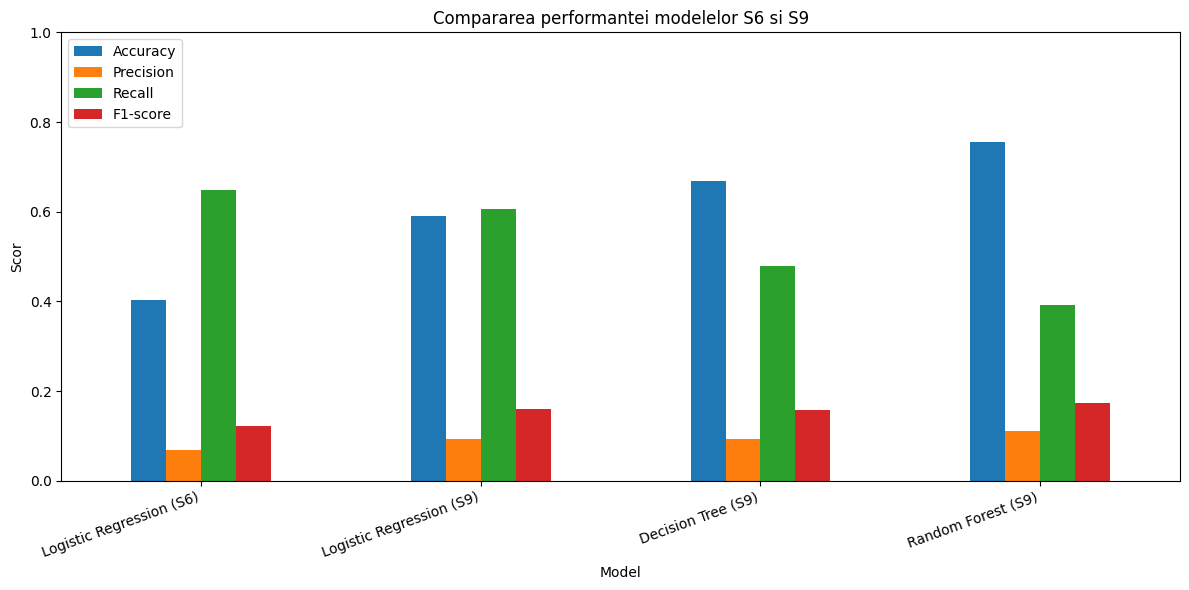

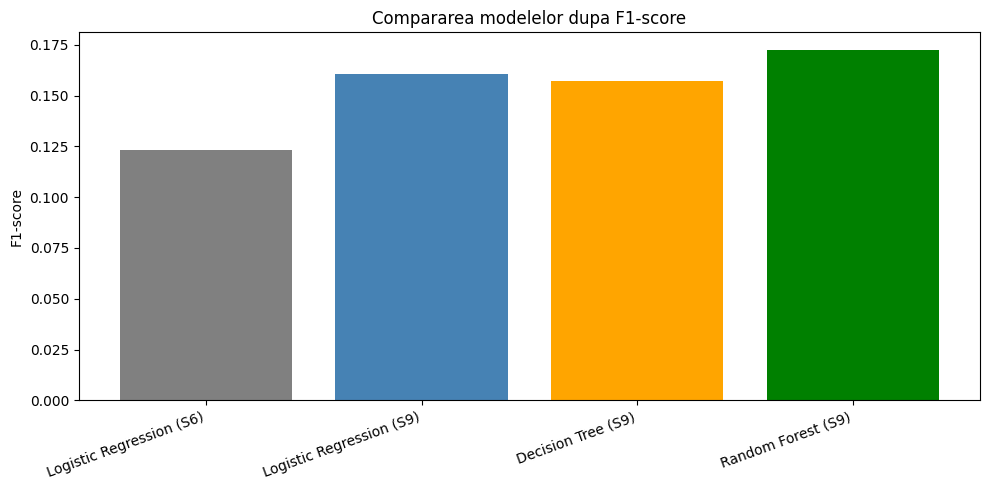

In [38]:
# S9 - Compararea rezultatelor S6 si S9

import matplotlib.pyplot as plt

rezultat_s6 = pd.DataFrame([{
    "Model": "Logistic Regression (S6)",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1
}])

rezultate_s9_comparatie = tabel_rezultate_s9.copy()

rezultate_s9_comparatie["Model"] = (
    rezultate_s9_comparatie["Model"] + " (S9)"
)

comparatie_s6_s9 = pd.concat(
    [rezultat_s6, rezultate_s9_comparatie],
    ignore_index=True
)

print("Compararea rezultatelor S6 si S9:")
display(comparatie_s6_s9.round(4))

# Grafic comparativ pentru toti indicatorii

comparatie_s6_s9.set_index("Model").plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Compararea performantei modelelor S6 si S9")
plt.ylabel("Scor")
plt.xlabel("Model")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

# Grafic dedicat indicatorului F1-score

plt.figure(figsize=(10, 5))

plt.bar(
    comparatie_s6_s9["Model"],
    comparatie_s6_s9["F1-score"],
    color=["gray", "steelblue", "orange", "green"]
)

plt.title("Compararea modelelor dupa F1-score")
plt.ylabel("F1-score")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 9. Inregistrarea experimentelor in Weights & Biases

Pentru monitorizarea experimentelor din etapa S9 voi
utiliza platforma Weights & Biases.

Voi inregistra separat rezultatele celor trei modele:
Logistic Regression, Decision Tree si Random Forest.

Pentru fiecare model voi salva hiperparametrii optimi,
rezultatul validarii incrucisate si indicatorii obtinuti
pe setul de testare: Accuracy, Precision, Recall si F1-score.

Astfel, voi putea compara experimentele din etapa S9
cu experimentul initial realizat in etapa S6.

In [39]:
# S9 - Inregistrarea experimentelor in Weights & Biases

import wandb

for rezultat in rezultate_cv_s9:

    nume = rezultat["Model"]

    metrici = tabel_rezultate_s9.loc[
        tabel_rezultate_s9["Model"] == nume
    ].iloc[0]

    with wandb.init(
        entity="teodorapeanca-university-of-craiova",
        project="ECommerce-Customer-Behavior-ML",
        name="S9-" + nume.replace(" ", "-"),
        group="S9",
        job_type="training",
        config={
            "model": nume,
            "numar_caracteristici": 5,
            "numar_exemple": len(X_s9),
            "hiperparametri": rezultat["Hiperparametri"]
        }
    ) as run:

        run.log({
            "accuracy": float(metrici["Accuracy"]),
            "precision": float(metrici["Precision"]),
            "recall": float(metrici["Recall"]),
            "f1_score": float(metrici["F1-score"]),
            "f1_cv": float(rezultat["F1-score validare"])
        })

    print("Experiment inregistrat:", nume)

print("\nInregistrarea experimentelor S9 a fost finalizata!")

wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261124_135706-pqve1a8m
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run S9-Logistic-Regression
wandb: ⭐️ View project at https://wandb.ai/teodorapeanca-university-of-craiova/ECommerce-Customer-Behavior-ML
wandb: 🚀 View run at https://wandb.ai/teodorapeanca-university-of-craiova/ECommerce-Customer-Behavior-ML/runs/pqve1a8m
wandb: updating run metadata; uploading summary
wandb: uploading requirements.txt; uploading wandb-summary.json; uploading config.yaml; uploading wandb-metadata.json
wandb: 
wandb: Run history:
wandb:  accuracy ▁
wandb:     f1_cv ▁
wandb:  f1_score ▁
wandb: precision ▁
wandb:    recall ▁
wandb: 
wandb: Run summary:
wandb:  accuracy 0.59066
wandb:     f1_cv 0.15768
wandb:  f1_score 0.16053
wandb: precision 0.09253
wandb:    recall 0.60552
wandb: 
wandb: 🚀 View run S9-Logistic-Regression at: https://wandb.ai/teodorapeanca-university-of-craiova/

Experiment inregistrat: Logistic Regression


wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261124_135708-jw5zxtp5
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run S9-Decision-Tree
wandb: ⭐️ View project at https://wandb.ai/teodorapeanca-university-of-craiova/ECommerce-Customer-Behavior-ML
wandb: 🚀 View run at https://wandb.ai/teodorapeanca-university-of-craiova/ECommerce-Customer-Behavior-ML/runs/jw5zxtp5
wandb: updating run metadata; uploading summary
wandb: updating run metadata
wandb: 
wandb: Run history:
wandb:  accuracy ▁
wandb:     f1_cv ▁
wandb:  f1_score ▁
wandb: precision ▁
wandb:    recall ▁
wandb: 
wandb: Run summary:
wandb:  accuracy 0.66747
wandb:     f1_cv 0.16204
wandb:  f1_score 0.15696
wandb: precision 0.09386
wandb:    recall 0.4789
wandb: 
wandb: 🚀 View run S9-Decision-Tree at: https://wandb.ai/teodorapeanca-university-of-craiova/ECommerce-Customer-Behavior-ML/runs/jw5zxtp5
wandb: ⭐️ View project at: https://wandb.ai/teodorapeanca

Experiment inregistrat: Decision Tree


wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261124_135710-j36vhxnb
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run S9-Random-Forest
wandb: ⭐️ View project at https://wandb.ai/teodorapeanca-university-of-craiova/ECommerce-Customer-Behavior-ML
wandb: 🚀 View run at https://wandb.ai/teodorapeanca-university-of-craiova/ECommerce-Customer-Behavior-ML/runs/j36vhxnb
wandb: updating run metadata; uploading summary
wandb: 
wandb: Run history:
wandb:  accuracy ▁
wandb:     f1_cv ▁
wandb:  f1_score ▁
wandb: precision ▁
wandb:    recall ▁
wandb: 
wandb: Run summary:
wandb:  accuracy 0.75635
wandb:     f1_cv 0.16921
wandb:  f1_score 0.17249
wandb: precision 0.1105
wandb:    recall 0.39286
wandb: 
wandb: 🚀 View run S9-Random-Forest at: https://wandb.ai/teodorapeanca-university-of-craiova/ECommerce-Customer-Behavior-ML/runs/j36vhxnb
wandb: ⭐️ View project at: https://wandb.ai/teodorapeanca-university-of-craiova/EComme

Experiment inregistrat: Random Forest

Inregistrarea experimentelor S9 a fost finalizata!


## 10. Concluziile etapei S9

În această etapă am îmbunătățit modelul inițial prin introducerea unor caracteristici suplimentare și prin testarea mai multor algoritmi de clasificare.

Am utilizat Logistic Regression, Decision Tree și Random Forest și am optimizat hiperparametrii acestora prin validare încrucișată.

Cel mai bun rezultat în funcție de F1-score a fost obținut de modelul Random Forest.

Comparativ cu modelul inițial din S6, F1-score a crescut de la 12,32% la 17,25%, ceea ce reprezintă o îmbunătățire relativă de aproximativ 40%.

Deși rezultatele s-au îmbunătățit, precizia rămâne redusă, iar modelul identifică mai puține dintre achizițiile reale. Performanța sistemului poate fi îmbunătățită în continuare.

Toate experimentele au fost înregistrate în Weights & Biases.